
# Modelado estadístico de factores asociados al fracaso técnico en procedimientos de CPRE asistidos por SpyGlass

**Proyecto:** SpyGlass   
**Metodología:** Regresión logística penalizada de Firth  
**Enfoque:** Evaluación de factores asociados al fracaso técnico y a la necesidad de nuevas intervenciones

**Autores:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co), Paula Gómez Vargas [✉](mailto:apaulag@uninorte.edu.co)



## 1. Introducción

El presente notebook desarrolla el modelado estadístico de los factores asociados al fracaso técnico en procedimientos de colangiopancreatografía retrógrada endoscópica (CPRE) asistidos por SpyGlass, a partir de la cohorte institucional previamente depurada y caracterizada durante el análisis exploratorio de datos (EDA).

**El objetivo principal es evaluar la asociación entre el tamaño, número y localización anatómica de los cálculos biliares y la probabilidad de fracaso técnico del procedimiento**, con el propósito de identificar características que permitan anticipar procedimientos de mayor complejidad. De manera complementaria, se estudiará la necesidad de nuevas intervenciones, siempre que la información disponible permita definir adecuadamente este desenlace.

Para ello, se implementarán modelos de regresión logística penalizada mediante el método de Firth, apropiados para escenarios con muestras pequeñas, eventos poco frecuentes y posibles problemas de separación completa o cuasicompleta.

## 2. Preparación de datos

### 2.1 Librerías y environment

In [1]:

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display, Markdown

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\SpyGlass")

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"
RUTA_SALIDA = RUTA_PROYECTO / "salidas_modelado"

sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *

HOJA = 0
N_ESPERADO = 145
SEMILLA = 2026
ALFA = 0.05

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

### 2.2 Carga de la cohorte analítica

In [2]:

ruta_archivo = RUTA_DATOS / "dataset_limpio_v2.xlsx"

df_spyglass = pd.read_excel(ruta_archivo, sheet_name=HOJA)

df_spyglass = (
    df_spyglass.loc[df_spyglass["ID procedimiento"] != 153]
    .copy()
    .reset_index(drop=True)
)

assert len(df_spyglass) == N_ESPERADO, (
    f"Se esperaban {N_ESPERADO} registros, "
    f"pero se encontraron {len(df_spyglass)}."
)

print(f"Dimensiones de la cohorte analítica: {df_spyglass.shape}")


Dimensiones de la cohorte analítica: (145, 81)



### 2.3. Identificación de variables para el modelado

Se identifican las variables de la cohorte relacionadas con los desenlaces de interés y las características de la carga litiásica. Esta selección permite reconocer los campos disponibles para la construcción de los modelos de regresión logística de Firth y establecer las variables que requieren revisión o transformación antes del ajuste.


In [3]:

patrones = [
    "FRACASO", "EXITO", "EXITOSO", "TECNICO",
    "TERAPEUTICO", "CALCULO", "LITIASIS",
    "TAMANO", "UBICACION", "LOCALIZACION",
    "INTERVENCION", "PROCEDIMIENTO"
]

columnas_modelado = [
    col for col in df_spyglass.columns
    if any(p in col.upper() for p in patrones)
]

for col in columnas_modelado:
    print(col)


ID procedimiento
FECHA PROCEDIMIENTO
IND_COLEDOCOLITIASIS
IND_LITIASIS_INTRAHEPATICA
NUMERO DE PROCEDIMIENTOS
TAMAÑO DE CALCULO MM
N_CALCULOS
NOTA_TAMANO_CALCULO
TIPOS DE CALCULO
UBICACION DEL CALCULO
UBICACION DE LA ESTENOSIS
REINTERVENCIONES BILIARES
FRACASO TERAPEUTICO



**Selección de variables para el modelado**

A partir de las columnas identificadas, se seleccionan las variables directamente relacionadas con los objetivos del estudio, distinguiendo entre desenlaces, predictores principales y variables auxiliares.

| Variable | Función | Justificación |
|---|---|---|
| `FRACASO TERAPEUTICO` | Desenlace principal | Permite evaluar la asociación entre las características de los cálculos y el fracaso terapéutico del procedimiento. |
| `REINTERVENCIONES BILIARES` | Desenlace secundario | Permite estudiar la relación entre las características litiásicas y la necesidad de intervenciones adicionales. |
| `TAMAÑO DE CALCULO MM` | Predictor | Representa el tamaño del cálculo y permite evaluar su asociación con el desenlace. |
| `N_CALCULOS` | Predictor | Cuantifica el número de cálculos y permite estudiar el efecto de la carga litiásica. |
| `UBICACION DEL CALCULO` | Predictor | Permite evaluar diferencias según la localización anatómica de los cálculos. |
| `NOTA_TAMANO_CALCULO` | Variable auxiliar | Facilita la revisión y validación de los valores registrados para el tamaño de los cálculos. |

Adicionalmente, se conservan como variables auxiliares `ID procedimiento`, para mantener la trazabilidad de los registros, e `IND_LITIASIS_INTRAHEPATICA`, para contrastar la clasificación anatómica cuando corresponda.

Las demás columnas identificadas no se incorporan inicialmente, dado que no forman parte de los predictores definidos para este análisis. Su inclusión posterior requeriría una justificación clínica y estadística específica.



### 2.4. Verificación de las variables del modelo

Se examinan los tipos de datos, la disponibilidad de registros y los valores observados en las variables seleccionadas. Esta verificación permite definir la codificación de los desenlaces y predictores, identificar posibles inconsistencias y determinar las condiciones iniciales para el ajuste de los modelos.

Se consideran como desenlaces candidatos el **fracaso terapéutico** y las **reintervenciones biliares**, mientras que el **tamaño, número y ubicación de los cálculos** constituyen los predictores principales. La variable `NOTA_TAMANO_CALCULO` se incluye como información complementaria para verificar el registro del tamaño de los cálculos.


In [6]:

variables_modelo = [
    "FRACASO TERAPEUTICO",
    "REINTERVENCIONES BILIARES",
    "TAMAÑO DE CALCULO MM",
    "N_CALCULOS",
    "UBICACION DEL CALCULO",
    "NOTA_TAMANO_CALCULO"
]

n = len(df_spyglass)

resumen_modelo = pd.DataFrame({
    "Variable": variables_modelo,
    "Disponibles": df_spyglass[variables_modelo].notna().sum().values,
    "Faltantes": df_spyglass[variables_modelo].isna().sum().values
})

resumen_modelo["Disponibles (%)"] = (
    resumen_modelo["Disponibles"] / n * 100
)

resumen_modelo["Faltantes (%)"] = (
    resumen_modelo["Faltantes"] / n * 100
)

resumen_modelo = resumen_modelo[
    ["Variable", "Disponibles", "Disponibles (%)",
     "Faltantes", "Faltantes (%)"]
]


estilo_tabla = [
    {"selector": "table", "props": [
        ("border-collapse", "collapse"),
        ("margin", "15px auto"),
        ("font-family", "Arial, sans-serif"),
        ("font-size", "13px"),
        ("border", "2px solid black"),
        ("color", "#111111")
    ]},
    {"selector": "th", "props": [
        ("background-color", "#17365D"),
        ("color", "#FFFFFF"),
        ("border", "1px solid black"),
        ("padding", "10px 14px"),
        ("text-align", "center")
    ]},
    {"selector": "td", "props": [
        ("color", "#111111"),
        ("border", "1px solid black"),
        ("padding", "8px 14px"),
        ("text-align", "center")
    ]},
    {"selector": "tbody tr:nth-child(odd) td", "props": [
        ("background-color", "#FFFFFF"),
        ("color", "#111111")
    ]},
    {"selector": "tbody tr:nth-child(even) td", "props": [
        ("background-color", "#EAF1F8"),
        ("color", "#111111")
    ]},
    {"selector": "caption", "props": [
        ("caption-side", "top"),
        ("color", "#FFFFFF"),
        ("font-size", "14px"),
        ("font-weight", "bold"),
        ("padding", "8px")
    ]}
]


display(
    resumen_modelo.style
    .hide(axis="index")
    .format({
        "Disponibles (%)": "{:.1f}%",
        "Faltantes (%)": "{:.1f}%"
    })
    .set_table_styles(estilo_tabla)
    .set_caption("Tabla 1. Disponibilidad de variables para el modelado")
)

desenlaces = [
    "FRACASO TERAPEUTICO",
    "REINTERVENCIONES BILIARES"
]

filas = []

for variable in desenlaces:
    serie = (
        df_spyglass[variable]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    for categoria, frecuencia in serie.value_counts(dropna=False).items():
        filas.append({
            "Desenlace": variable,
            "Categoría": categoria,
            "Frecuencia": frecuencia,
            "Porcentaje (%)": frecuencia / n * 100
        })

tabla_desenlaces = pd.DataFrame(filas)

display(
    tabla_desenlaces.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}%"})
    .set_table_styles(estilo_tabla)
    .set_caption("Tabla 2. Distribución de los desenlaces")
)



Variable,Disponibles,Disponibles (%),Faltantes,Faltantes (%)
FRACASO TERAPEUTICO,145,100.0%,0,0.0%
REINTERVENCIONES BILIARES,145,100.0%,0,0.0%
TAMAÑO DE CALCULO MM,76,52.4%,69,47.6%
N_CALCULOS,24,16.6%,121,83.4%
UBICACION DEL CALCULO,108,74.5%,37,25.5%
NOTA_TAMANO_CALCULO,37,25.5%,108,74.5%


Desenlace,Categoría,Frecuencia,Porcentaje (%)
FRACASO TERAPEUTICO,NO,117,80.7%
FRACASO TERAPEUTICO,SI,28,19.3%
REINTERVENCIONES BILIARES,NO,96,66.2%
REINTERVENCIONES BILIARES,SI,49,33.8%




De los 145 procedimientos analizados, 28 (19,3 %) registraron fracaso terapéutico y 49 (33,8 %) requirieron reintervenciones biliares. Ambos desenlaces cuentan con información completa, lo que permite trabajar con la totalidad de la cohorte al evaluar cada uno por separado.

La principal limitación está en los predictores. Aunque la ubicación del cálculo se encuentra registrada en el 74,5 % de los procedimientos y el tamaño en el 52,4 %, el número de cálculos solo está disponible en 24 casos (16,6 %). 



### 2.5. Estandarización y construcción de variables para el modelado

#### 2.5.1. Revisión de información complementaria sobre los cálculos

Dada la baja disponibilidad de registros en las variables numéricas de tamaño y número de cálculos, se revisa la información contenida en `NOTA_TAMANO_CALCULO` para identificar valores que puedan recuperarse directamente de las descripciones clínicas.

Se seleccionan los procedimientos con información faltante en alguna de estas variables y con una anotación disponible, conservando el identificador del procedimiento para verificar cada registro antes de incorporar nuevos valores.


In [7]:

columnas_revision = [
    "ID procedimiento",
    "TAMAÑO DE CALCULO MM",
    "N_CALCULOS",
    "NOTA_TAMANO_CALCULO"
]

mascara_revision = (
    df_spyglass["NOTA_TAMANO_CALCULO"].notna()
    & (
        df_spyglass["TAMAÑO DE CALCULO MM"].isna()
        | df_spyglass["N_CALCULOS"].isna()
    )
)

registros_revision = (
    df_spyglass.loc[mascara_revision, columnas_revision]
    .sort_values("ID procedimiento")
    .reset_index(drop=True)
)

print(f"Registros candidatos a revisión: {len(registros_revision)}")

estilo_revision = [
    {"selector": "table", "props": [
        ("border-collapse", "collapse"),
        ("margin", "15px auto"),
        ("border", "2px solid black"),
        ("font-family", "Arial, sans-serif"),
        ("font-size", "13px")
    ]},
    {"selector": "th", "props": [
        ("background-color", "#17365D"),
        ("color", "#FFFFFF"),
        ("border", "1px solid black"),
        ("padding", "10px"),
        ("text-align", "center")
    ]},
    {"selector": "td", "props": [
        ("color", "#111111"),
        ("border", "1px solid black"),
        ("padding", "8px 12px"),
        ("text-align", "center")
    ]},
    {"selector": "tbody tr:nth-child(odd) td", "props": [
        ("background-color", "#FFFFFF")
    ]},
    {"selector": "tbody tr:nth-child(even) td", "props": [
        ("background-color", "#EAF1F8")
    ]},
    {"selector": "caption", "props": [
        ("caption-side", "top"),
        ("color", "#FFFFFF"),
        ("font-weight", "bold"),
        ("padding", "8px")
    ]}
]

display(
    registros_revision.style
    .hide(axis="index")
    .format({
        "TAMAÑO DE CALCULO MM": "{:.1f}",
        "N_CALCULOS": "{:.0f}"
    }, na_rep="—")
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 3. Registros candidatos a recuperación de información")
)


Registros candidatos a revisión: 13


ID procedimiento,TAMAÑO DE CALCULO MM,N_CALCULOS,NOTA_TAMANO_CALCULO
11,40.0,—,40 X 20 MM
30,25.0,—,2.5 X 1.2 CMS
34,40.0,—,4CM
61,20.0,—,2 CMS
62,12.0,—,EL MAYOR DE 12 MM
66,25.0,—,2.5 CMS
69,25.0,—,2.5 CMS
78,—,—,2020-12-01 00:00:00
86,15.0,—,MAYOR 15 MM
107,12.0,—,EL MAYOR DE 12 MM




Se identificaron 13 procedimientos con anotaciones clínicas disponibles y valores faltantes en alguna de las variables numéricas. En 12 de ellos, el tamaño del cálculo ya estaba registrado, mientras que el procedimiento restante contenía una fecha que no permite recuperar información válida.

Las anotaciones tampoco permitieron establecer nuevos valores exactos para el número de cálculos. Por tanto, se conservarán los registros numéricos originales, sin realizar modificaciones ni imputaciones. La variable `N_CALCULOS` continuará con 24 observaciones disponibles.



#### 2.5.2. Estandarización de la ubicación anatómica

La variable `UBICACION DEL CALCULO` contiene diferentes denominaciones para estructuras anatómicas similares, además de registros que mencionan múltiples localizaciones. Para su incorporación al modelo, se propone una clasificación en localización extrahepática, intrahepática y mixta, conservando una categoría no clasificable para los registros sin información suficiente.

Se revisan las descripciones originales antes de aplicar las reglas de clasificación, con el fin de mantener la correspondencia entre la información clínica y las categorías utilizadas en el modelado.


In [9]:

ubicaciones = (
    df_spyglass["UBICACION DEL CALCULO"]
    .value_counts(dropna=False)
    .rename_axis("Ubicación original")
    .reset_index(name="Frecuencia")
)

ubicaciones["Porcentaje (%)"] = (
    ubicaciones["Frecuencia"] / len(df_spyglass) * 100
)

display(
    ubicaciones.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}%"})
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 4. Descripciones originales de la ubicación de los cálculos")
)


Ubicación original,Frecuencia,Porcentaje (%)
COLEDOCO,37,25.5%
nan,37,25.5%
COLEDOCO MEDIAL,10,6.9%
NO APLICA,7,4.8%
COLEDOCO PROXIMAL,6,4.1%
COLEDODO,5,3.4%
COLEDOCO DISTAL,3,2.1%
INTRAHEPATICO DERECHO,3,2.1%
HEPATICO IZQUIERDO,3,2.1%
COLEDOCO DISTAL,2,1.4%




:::{admonition} Consideración metodológica
:class: note

Las ubicaciones registradas se agrupan en tres categorías anatómicas: **extrahepática, intrahepática y mixta**, según las estructuras descritas. Los registros sin información suficiente, no aplicables o correspondientes exclusivamente al conducto pancreático se mantienen como **no clasificables**.

Las localizaciones mixtas se conservan inicialmente como una categoría independiente. Su posible agrupación con las intrahepáticas se evaluará según la frecuencia de los eventos y la viabilidad estadística del modelo.

La clasificación se realiza sin modificar las descripciones originales, permitiendo verificar la correspondencia entre los registros clínicos y las categorías construidas.
:::






In [13]:

import re
import unicodedata

def normalizar_ubicacion(valor):
    if pd.isna(valor):
        return ""

    texto = str(valor).upper().strip()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto if not unicodedata.combining(c)
    )
    texto = re.sub(r"\s+", " ", texto)

    return texto


def clasificar_ubicacion(valor):
    texto = normalizar_ubicacion(valor)

    if texto in {"", "NO", "NO APLICA", "NO DESCRIBE"}:
        return "No clasificable"

    if "WIRSUNG" in texto or "WIRUSUNG" in texto:
        return "No clasificable"

    intra = any(p in texto for p in [
        "INTRAHEPAT",
        "HEPATOLITIASIS",
        "HEPATICO DERECHO",
        "HEPATICO IZQUIERDO"
    ])

    extra = any(p in texto for p in [
        "COLEDOCO",
        "COLEDODO",
        "COLODECO",
        "COLEDOCOLO",
        "EXTRAHEPAT",
        "HEPATICO COMUN",
        "VIA BILIAR PRINCIPAL",
        "VIA BILIAR PROXIMAL",
        "CONDUCTO CISTICO",
        "CONFLUENCIA ENTRE CONDUCTO CISTICO"
    ])

    if "INTRA Y EXTRAHEPATICA" in texto:
        return "Mixta"

    if intra and extra:
        return "Mixta"

    if intra:
        return "Intrahepática"

    if extra:
        return "Extrahepática"

    return "Revisión manual"


df_spyglass["UBICACION_MODELO"] = (
    df_spyglass["UBICACION DEL CALCULO"]
    .apply(clasificar_ubicacion)
)

#### 2.5.3. Verificación de la clasificación anatómica

Una vez estandarizadas las descripciones originales, se verifica la distribución de los procedimientos entre las categorías anatómicas definidas y se identifican los registros que requieren revisión manual.

Esta comprobación permite evaluar la consistencia de la clasificación y determinar si las categorías cuentan con suficiente representación para incorporarse al modelo de regresión logística de Firth. También permite establecer si resulta conveniente utilizar una clasificación binaria basada en la presencia de compromiso intrahepático.


In [16]:

if "UBICACION_MODELO" not in df_spyglass.columns:
    raise ValueError(
        "La variable UBICACION_MODELO no existe. "
        "Ejecuta primero el chunk de clasificación anatómica de la sección 2.5.2."
    )

resumen_ubicacion = (
    df_spyglass["UBICACION_MODELO"]
    .value_counts(dropna=False)
    .rename_axis("Clasificación anatómica")
    .reset_index(name="Frecuencia")
)

resumen_ubicacion["Porcentaje (%)"] = (
    resumen_ubicacion["Frecuencia"] / len(df_spyglass) * 100
)

display(
    resumen_ubicacion.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}%"})
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 6. Distribución de la clasificación anatómica")
)

pendientes_ubicacion = df_spyglass.loc[
    df_spyglass["UBICACION_MODELO"] == "Revisión manual",
    ["ID procedimiento", "UBICACION DEL CALCULO"]
]

print(f"Registros pendientes de clasificación: {len(pendientes_ubicacion)}")

if not pendientes_ubicacion.empty:
    display(
        pendientes_ubicacion.style
        .hide(axis="index")
        .set_table_styles(estilo_revision)
        .set_caption("Registros pendientes de revisión anatómica")
    )


Clasificación anatómica,Frecuencia,Porcentaje (%)
Extrahepática,79,54.5%
No clasificable,50,34.5%
Intrahepática,10,6.9%
Mixta,6,4.1%


Registros pendientes de clasificación: 0


La localización extrahepática fue la más frecuente, con 79 procedimientos (54,5 %), seguida de la intrahepática con 10 (6,9 %) y la mixta con 6 (4,1 %). Los 50 registros restantes (34,5 %) quedaron como no clasificables, debido a la ausencia de información anatómica aplicable o suficiente.

La clasificación permitió asignar una localización anatómica a 95 procedimientos, sin dejar registros pendientes de revisión manual. Sin embargo, las categorías intrahepática y mixta presentan frecuencias reducidas, por lo que se evaluará su agrupación para evitar una fragmentación excesiva de los datos durante el modelado.



#### 2.5.4. Construcción del predictor de compromiso intrahepático

Para incorporar la ubicación anatómica al modelo, se construye una variable binaria que identifica la presencia de compromiso intrahepático. Se agrupan las localizaciones intrahepáticas y mixtas en una misma categoría, mientras que las exclusivamente extrahepáticas constituyen el grupo de referencia.

Esta codificación reduce el número de parámetros necesarios para representar la ubicación anatómica y permite evaluar su asociación con los desenlaces de interés.


In [17]:

mapa_intrahepatico = {
    "Extrahepática": 0,
    "Intrahepática": 1,
    "Mixta": 1
}

df_spyglass["COMPROMISO_INTRAHEPATICO"] = (
    df_spyglass["UBICACION_MODELO"]
    .map(mapa_intrahepatico)
    .astype("Int64")
)

resumen_intrahepatico = (
    df_spyglass["COMPROMISO_INTRAHEPATICO"]
    .map({
        0: "Sin compromiso intrahepático",
        1: "Con compromiso intrahepático"
    })
    .fillna("No clasificable")
    .value_counts()
    .rename_axis("Categoría")
    .reset_index(name="Frecuencia")
)

resumen_intrahepatico["Porcentaje (%)"] = (
    resumen_intrahepatico["Frecuencia"] / len(df_spyglass) * 100
)

display(
    resumen_intrahepatico.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}%"})
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 7. Codificación del compromiso intrahepático")
)


Categoría,Frecuencia,Porcentaje (%)
Sin compromiso intrahepático,79,54.5%
No clasificable,50,34.5%
Con compromiso intrahepático,16,11.0%





De los 95 procedimientos con ubicación anatómica clasificable, 79 (83,2 %) corresponden a localizaciones exclusivamente extrahepáticas y 16 (16,8 %) presentan compromiso intrahepático, incluyendo los casos mixtos. Los 50 registros no clasificables se mantienen como valores faltantes para este predictor.

Esta codificación permite evaluar el compromiso intrahepático mediante una sola variable binaria, aunque será necesario comprobar cuántos eventos de fracaso terapéutico y reintervención se presentan en cada grupo antes de ajustar los modelos.



#### 2.5.5. Codificación de los desenlaces

Se transforman las variables `FRACASO TERAPEUTICO` y `REINTERVENCIONES BILIARES` a formato binario, asignando el valor 1 a la presencia del evento y 0 a su ausencia.

La transformación incluye la normalización de espacios y diferencias de escritura, conservando las columnas originales. Posteriormente, se verifica la frecuencia de los eventos y la consistencia de la codificación para su utilización como variables dependientes en los modelos de regresión logística de Firth.


In [18]:

desenlaces_originales = {
    "FRACASO TERAPEUTICO": "FRACASO_MODELO",
    "REINTERVENCIONES BILIARES": "REINTERVENCION_MODELO"
}

for original, nueva in desenlaces_originales.items():
    valores = (
        df_spyglass[original]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    df_spyglass[nueva] = (
        valores.map({"SI": 1, "NO": 0})
        .astype("Int64")
    )

    assert df_spyglass[nueva].notna().all(), (
        f"Se encontraron valores sin codificar en {original}"
    )

filas_desenlaces = []

for variable, nombre in [
    ("FRACASO_MODELO", "Fracaso terapéutico"),
    ("REINTERVENCION_MODELO", "Reintervención biliar")
]:
    conteos = df_spyglass[variable].value_counts()

    for valor, categoria in [(0, "No"), (1, "Sí")]:
        frecuencia = int(conteos.get(valor, 0))

        filas_desenlaces.append({
            "Desenlace": nombre,
            "Evento": categoria,
            "Frecuencia": frecuencia,
            "Porcentaje (%)": frecuencia / len(df_spyglass) * 100
        })

tabla_codificacion = pd.DataFrame(filas_desenlaces)

display(
    tabla_codificacion.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}%"})
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 8. Codificación binaria de los desenlaces")
)


Desenlace,Evento,Frecuencia,Porcentaje (%)
Fracaso terapéutico,No,117,80.7%
Fracaso terapéutico,Sí,28,19.3%
Reintervención biliar,No,96,66.2%
Reintervención biliar,Sí,49,33.8%


La codificación binaria conservó los 145 procedimientos de la cohorte. Se registraron 28 casos de fracaso terapéutico (19,3 %) y 49 de reintervención biliar (33,8 %), sin valores faltantes en ninguno de los desenlaces.

Ambas variables quedaron preparadas para su incorporación como desenlaces en los modelos de regresión logística de Firth.


### 2.6. Evaluación de la viabilidad de los modelos

Se evalúa la disponibilidad conjunta de los predictores y desenlaces para determinar el tamaño efectivo de las muestras de modelado. Para cada combinación se contabilizan los procedimientos completos, los eventos observados y los casos sin evento.

Esta verificación permite identificar modelos con información insuficiente, especialmente aquellos que incorporan el número de cálculos, y establecer qué combinaciones de predictores pueden considerarse para el ajuste mediante regresión logística de Firth.



In [19]:

predictores = {
    "Tamaño del cálculo": ["TAMAÑO DE CALCULO MM"],
    "Número de cálculos": ["N_CALCULOS"],
    "Compromiso intrahepático": ["COMPROMISO_INTRAHEPATICO"],
    "Tamaño + Número": [
        "TAMAÑO DE CALCULO MM",
        "N_CALCULOS"
    ],
    "Tamaño + Ubicación": [
        "TAMAÑO DE CALCULO MM",
        "COMPROMISO_INTRAHEPATICO"
    ],
    "Número + Ubicación": [
        "N_CALCULOS",
        "COMPROMISO_INTRAHEPATICO"
    ],
    "Modelo completo": [
        "TAMAÑO DE CALCULO MM",
        "N_CALCULOS",
        "COMPROMISO_INTRAHEPATICO"
    ]
}

desenlaces = {
    "Fracaso terapéutico": "FRACASO_MODELO",
    "Reintervención biliar": "REINTERVENCION_MODELO"
}

resultados_viabilidad = []

for nombre_des, col_des in desenlaces.items():
    for nombre_pred, cols_pred in predictores.items():
        datos = df_spyglass[
            [col_des] + cols_pred
        ].dropna()

        n = len(datos)
        eventos = int(datos[col_des].sum())
        no_eventos = n - eventos

        resultados_viabilidad.append({
            "Desenlace": nombre_des,
            "Predictores": nombre_pred,
            "N": n,
            "Eventos": eventos,
            "No eventos": no_eventos,
            "Eventos (%)": eventos / n * 100 if n else np.nan
        })

tabla_viabilidad = pd.DataFrame(resultados_viabilidad)

display(
    tabla_viabilidad.style
    .hide(axis="index")
    .format({"Eventos (%)": "{:.1f}%"}, na_rep="—")
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 9. Disponibilidad de eventos según la especificación del modelo")
)


Desenlace,Predictores,N,Eventos,No eventos,Eventos (%)
Fracaso terapéutico,Tamaño del cálculo,76,10,66,13.2%
Fracaso terapéutico,Número de cálculos,24,4,20,16.7%
Fracaso terapéutico,Compromiso intrahepático,95,15,80,15.8%
Fracaso terapéutico,Tamaño + Número,24,4,20,16.7%
Fracaso terapéutico,Tamaño + Ubicación,71,9,62,12.7%
Fracaso terapéutico,Número + Ubicación,24,4,20,16.7%
Fracaso terapéutico,Modelo completo,24,4,20,16.7%
Reintervención biliar,Tamaño del cálculo,76,19,57,25.0%
Reintervención biliar,Número de cálculos,24,4,20,16.7%
Reintervención biliar,Compromiso intrahepático,95,25,70,26.3%


La disponibilidad de información reduce considerablemente el tamaño de las muestras de modelado. Para el fracaso terapéutico, el tamaño del cálculo permite trabajar con 76 procedimientos y 10 eventos, mientras que el compromiso intrahepático dispone de 95 procedimientos y 15 eventos. Al incluir ambos predictores, la muestra se reduce a 71 procedimientos con 9 fracasos.

En el caso de las reintervenciones biliares, las muestras contienen un mayor número de eventos: 19 para el tamaño del cálculo, 25 para el compromiso intrahepático y 16 cuando se consideran conjuntamente.

El número de cálculos presenta la mayor limitación, con apenas 24 procedimientos y 4 eventos para cada desenlace. Su incorporación al modelo completo reduciría el análisis a esos mismos 24 registros, por lo que no se considera adecuado incluirlo en el ajuste multivariable principal.



### 2.7. Verificación de eventos según el compromiso intrahepático

Se examina la distribución de los desenlaces según la presencia o ausencia de compromiso intrahepático, utilizando únicamente los procedimientos con localización anatómica clasificable.

Esta comprobación permite identificar categorías con pocos eventos o ausencia de alguno de los desenlaces, situaciones que pueden generar estimaciones inestables o problemas de separación en la regresión logística. Los resultados se utilizarán para confirmar la viabilidad del predictor anatómico antes del ajuste.


In [20]:

filas_eventos = []

for nombre, desenlace in desenlaces.items():
    datos = df_spyglass[
        ["COMPROMISO_INTRAHEPATICO", desenlace]
    ].dropna()

    for valor, categoria in [
        (0, "Sin compromiso intrahepático"),
        (1, "Con compromiso intrahepático")
    ]:
        grupo = datos.loc[
            datos["COMPROMISO_INTRAHEPATICO"] == valor
        ]

        n = len(grupo)
        eventos = int(grupo[desenlace].sum())

        filas_eventos.append({
            "Desenlace": nombre,
            "Compromiso intrahepático": categoria,
            "N": n,
            "Eventos": eventos,
            "No eventos": n - eventos,
            "Eventos (%)": eventos / n * 100 if n else np.nan
        })

tabla_eventos_anatomia = pd.DataFrame(filas_eventos)

display(
    tabla_eventos_anatomia.style
    .hide(axis="index")
    .format({"Eventos (%)": "{:.1f}%"})
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 10. Eventos según compromiso intrahepático")
)


Desenlace,Compromiso intrahepático,N,Eventos,No eventos,Eventos (%)
Fracaso terapéutico,Sin compromiso intrahepático,79,12,67,15.2%
Fracaso terapéutico,Con compromiso intrahepático,16,3,13,18.8%
Reintervención biliar,Sin compromiso intrahepático,79,20,59,25.3%
Reintervención biliar,Con compromiso intrahepático,16,5,11,31.2%





El fracaso terapéutico se presentó en el 15,2 % de los procedimientos sin compromiso intrahepático y en el 18,8 % de aquellos con compromiso intrahepático. Para las reintervenciones biliares, las proporciones fueron del 25,3 % y 31,2 %, respectivamente.

Aunque ambos desenlaces fueron ligeramente más frecuentes en el grupo con compromiso intrahepático, las diferencias observadas son pequeñas y este grupo cuenta con pocos eventos: 3 fracasos y 5 reintervenciones. No se identificó separación completa en las comparaciones anatómicas, por lo que se conservará este predictor para el ajuste de los modelos de Firth.


:::{admonition} Consideración metodológica: exclusión del número de cálculos
:class: note

La variable `N_CALCULOS` fue construida durante la depuración a partir de los registros clínicos que permitían identificar explícitamente la cantidad de cálculos. Sin embargo, esta información solo estuvo disponible en **24 de los 145 procedimientos (16,6 %)**, debido a que en los registros restantes no se documentó la cantidad.

En esta submuestra se identificaron únicamente **4 eventos de fracaso terapéutico y 4 de reintervención biliar**, lo que limita considerablemente la precisión de las estimaciones. Por esta razón, el número de cálculos **no se incluirá en los modelos de regresión logística de Firth**. Tampoco se realizará imputación, dado que no existe información clínica suficiente para reconstruir los valores ausentes.

En consecuencia, el análisis inferencial se centrará en el **tamaño y la ubicación anatómica de los cálculos**, mientras que el número de cálculos se conservará únicamente como variable descriptiva en los procedimientos con información disponible.

:::


## 3. Implementación


### 3.1. Especificación de los modelos

Se empleará regresión logística penalizada mediante el método de Firth para estimar la asociación entre las características de los cálculos biliares y los desenlaces de interés. Este procedimiento incorpora una penalización basada en la información de Fisher, que reduce el sesgo de las estimaciones y permite obtener coeficientes finitos ante problemas de separación.

Se considerarán dos desenlaces binarios: **fracaso terapéutico** y **reintervención biliar**. Para cada uno se ajustarán modelos univariados con el tamaño del cálculo y el compromiso intrahepático como predictores. Adicionalmente, se evaluará un modelo conjunto con ambas variables, de carácter exploratorio debido al número limitado de eventos disponibles.

El número de cálculos no se incluirá en los modelos principales, dado que su disponibilidad se limita a 24 procedimientos y 4 eventos por desenlace.

Los resultados se expresarán mediante **odds ratios (OR)** e intervalos de confianza del 95 %, utilizando inferencia apropiada para la regresión penalizada de Firth.



### 3.2. Preparación de las matrices de modelado

Se construyen las muestras analíticas correspondientes a las seis especificaciones propuestas, seleccionando los procedimientos con información completa para cada desenlace y conjunto de predictores.

El tamaño del cálculo se expresa en unidades de 10 mm para facilitar la interpretación de los odds ratios, mientras que el compromiso intrahepático se incorpora como una variable binaria, tomando como referencia los procedimientos con localización exclusivamente extrahepática.

Las matrices se almacenan de manera independiente, conservando intacto el conjunto de datos original.


In [21]:

df_spyglass["TAMANO_10MM"] = (
    pd.to_numeric(
        df_spyglass["TAMAÑO DE CALCULO MM"],
        errors="coerce"
    ) / 10
)

especificaciones = {
    "F1": {
        "desenlace": "FRACASO_MODELO",
        "predictores": ["TAMANO_10MM"]
    },
    "F2": {
        "desenlace": "FRACASO_MODELO",
        "predictores": ["COMPROMISO_INTRAHEPATICO"]
    },
    "F3": {
        "desenlace": "FRACASO_MODELO",
        "predictores": ["TAMANO_10MM", "COMPROMISO_INTRAHEPATICO"]
    },
    "R1": {
        "desenlace": "REINTERVENCION_MODELO",
        "predictores": ["TAMANO_10MM"]
    },
    "R2": {
        "desenlace": "REINTERVENCION_MODELO",
        "predictores": ["COMPROMISO_INTRAHEPATICO"]
    },
    "R3": {
        "desenlace": "REINTERVENCION_MODELO",
        "predictores": ["TAMANO_10MM", "COMPROMISO_INTRAHEPATICO"]
    }
}

datos_modelos = {}

for nombre, config in especificaciones.items():
    columnas = [config["desenlace"]] + config["predictores"]

    datos_modelos[nombre] = (
        df_spyglass[columnas]
        .dropna()
        .astype(float)
        .copy()
    )

resumen_modelos = []

for nombre, datos in datos_modelos.items():
    desenlace = especificaciones[nombre]["desenlace"]
    n = len(datos)
    eventos = int(datos[desenlace].sum())

    resumen_modelos.append({
        "Modelo": nombre,
        "N": n,
        "Eventos": eventos,
        "No eventos": n - eventos,
        "Predictores": " + ".join(especificaciones[nombre]["predictores"])
    })

tabla_modelos = pd.DataFrame(resumen_modelos)

display(
    tabla_modelos.style
    .hide(axis="index")
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 11. Muestras analíticas para los modelos de Firth")
)


Modelo,N,Eventos,No eventos,Predictores
F1,76,10,66,TAMANO_10MM
F2,95,15,80,COMPROMISO_INTRAHEPATICO
F3,71,9,62,TAMANO_10MM + COMPROMISO_INTRAHEPATICO
R1,76,19,57,TAMANO_10MM
R2,95,25,70,COMPROMISO_INTRAHEPATICO
R3,71,16,55,TAMANO_10MM + COMPROMISO_INTRAHEPATICO


Las muestras analíticas quedaron conformadas según la disponibilidad de los predictores. Los modelos univariados incluyen entre 76 y 95 procedimientos, mientras que los modelos conjuntos se reducen a 71 registros.

El modelo conjunto de fracaso terapéutico (F3) dispone de apenas 9 eventos, frente a los 16 del modelo de reintervención biliar (R3). Por tanto, ambos ajustes se considerarán exploratorios, con especial atención a la precisión de las estimaciones del modelo F3.


### 3.3. Implementación de la regresión logística de Firth

La regresión logística de Firth se implementa mediante la maximización de una función de log-verosimilitud penalizada, que incorpora la corrección de Jeffreys para reducir el sesgo de estimación y abordar posibles problemas de separación en muestras con pocos eventos.

La función objetivo se define como:

$$
\ell_F(\boldsymbol{\beta})
=\ell(\boldsymbol{\beta})
+
\frac{1}{2}\log\left|I(\boldsymbol{\beta})\right|
$$

donde:

- $\ell(\boldsymbol{\beta})$ representa la log-verosimilitud del modelo logístico convencional.
- $I(\boldsymbol{\beta})$ corresponde a la matriz de información de Fisher.
- $\boldsymbol{\beta}$ es el vector de coeficientes del modelo, incluido el intercepto.

La estimación de los parámetros se realizará mediante optimización numérica de la función penalizada. Posteriormente, los coeficientes se transformarán en **odds ratios (OR)** y se calcularán intervalos de confianza del 95 % mediante el perfil de verosimilitud penalizada.

Se verificará la convergencia de cada ajuste antes de interpretar las asociaciones entre los predictores y los desenlaces clínicos.



#### 3.3.1. Definición del estimador penalizado

Se implementa la función objetivo de la regresión logística de Firth mediante la log-verosimilitud binomial y la penalización de Jeffreys, calculada a partir del determinante de la matriz de información de Fisher.

La función se utilizará posteriormente para estimar los coeficientes mediante optimización numérica. Se incluye el intercepto en la matriz de diseño y se comprueba la validez numérica de la información de Fisher.


In [22]:

from scipy.special import expit
from scipy.optimize import minimize

def logverosimilitud_firth(beta, X, y):
    eta = X @ beta
    p = expit(eta)

    loglik = np.sum(
        y * eta - np.logaddexp(0, eta)
    )

    w = np.clip(p * (1 - p), 1e-12, None)
    informacion = X.T @ (w[:, None] * X)

    signo, logdet = np.linalg.slogdet(informacion)

    if signo <= 0 or not np.isfinite(logdet):
        return np.inf

    return -(loglik + 0.5 * logdet)


def preparar_matriz_firth(datos, desenlace, predictores):
    y = datos[desenlace].to_numpy(dtype=float)

    X = datos[predictores].to_numpy(dtype=float)
    X = np.column_stack([np.ones(len(X)), X])

    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError("La matriz contiene valores no finitos.")

    if np.linalg.matrix_rank(X) < X.shape[1]:
        raise ValueError("La matriz de diseño no tiene rango completo.")

    if not np.isin(y, [0, 1]).all():
        raise ValueError("El desenlace debe ser binario.")

    return X, y



#### 3.3.2. Ajuste numérico y verificación de convergencia

Se implementa una rutina de optimización numérica para estimar los coeficientes que maximizan la log-verosimilitud penalizada de Firth. El procedimiento utiliza el algoritmo BFGS y verifica tanto el resultado de la optimización como la magnitud del gradiente de la función objetivo.

Inicialmente, se ajusta el modelo F1, que evalúa la asociación entre el tamaño del cálculo, expresado por incrementos de 10 mm, y el fracaso terapéutico. Este ajuste preliminar permite comprobar el funcionamiento del estimador antes de aplicarlo a las demás especificaciones.


In [26]:

def gradiente_firth(beta, X, y):
    p = expit(X @ beta)
    w = np.clip(p * (1 - p), 1e-12, None)

    informacion = X.T @ (w[:, None] * X)
    inversa = np.linalg.solve(informacion, X.T)

    h = w * np.sum(X * inversa.T, axis=1)

    score = X.T @ (y - p + h * (0.5 - p))

    return -score


def ajustar_firth(X, y, tolerancia=1e-5):
    beta_inicial = np.zeros(X.shape[1])

    resultado = minimize(
        logverosimilitud_firth,
        beta_inicial,
        args=(X, y),
        jac=gradiente_firth,
        method="BFGS",
        options={
            "gtol": 1e-8,
            "maxiter": 2000
        }
    )

    norma_gradiente = np.max(
        np.abs(gradiente_firth(resultado.x, X, y))
    )

    return {
        "coeficientes": resultado.x,
        "convergencia_optimizador": resultado.success,
        "gradiente_maximo": norma_gradiente,
        "convergencia_numerica": (
            np.isfinite(resultado.fun)
            and norma_gradiente < tolerancia
        ),
        "loglik_penalizada": -resultado.fun,
        "iteraciones": resultado.nit,
        "mensaje": resultado.message
    }


config_f1 = especificaciones["F1"]

X_f1, y_f1 = preparar_matriz_firth(
    datos_modelos["F1"],
    config_f1["desenlace"],
    config_f1["predictores"]
)

ajuste_f1 = ajustar_firth(X_f1, y_f1)

tabla_ajuste_f1 = pd.DataFrame({
    "Parámetro": [
        "Intercepto",
        "Tamaño del cálculo (10 mm)"
    ],
    "Coeficiente": ajuste_f1["coeficientes"],
    "OR": np.exp(ajuste_f1["coeficientes"])
})

display(
    tabla_ajuste_f1.style
    .hide(axis="index")
    .format({
        "Coeficiente": "{:.4f}",
        "OR": "{:.4f}"
    })
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 12. Estimaciones preliminares del modelo F1")
)

print(f"Convergencia del optimizador: {ajuste_f1['convergencia_optimizador']}")
print(f"Convergencia numérica: {ajuste_f1['convergencia_numerica']}")
print(f"Gradiente máximo: {ajuste_f1['gradiente_maximo']:.2e}")
print(f"Iteraciones: {ajuste_f1['iteraciones']}")
print(f"Mensaje: {ajuste_f1['mensaje']}")


Parámetro,Coeficiente,OR
Intercepto,-1.2197,0.2953
Tamaño del cálculo (10 mm),-0.3493,0.7052


Convergencia del optimizador: True
Convergencia numérica: True
Gradiente máximo: 2.44e-10
Iteraciones: 11
Mensaje: Optimization terminated successfully.


El modelo F1 estimó un coeficiente negativo para el tamaño del cálculo ($\beta=-0.3493$), con un odds ratio de 0.7052. Esto indica que, por cada incremento de 10 mm en el tamaño del cálculo, las *odds* estimadas de fracaso terapéutico disminuyen aproximadamente un 29.5 %.

El procedimiento de optimización convergió satisfactoriamente después de 11 iteraciones, con un gradiente máximo de $2.44 \times 10^{-10}$, lo que respalda la estabilidad numérica de la estimación.

Aunque se observa una asociación negativa entre el tamaño del cálculo y el fracaso terapéutico, todavía no es posible establecer su significancia estadística. Para ello, se calcularán los intervalos de confianza mediante el perfil de verosimilitud penalizada.



#### 3.3.3. Intervalos de confianza por perfil de verosimilitud penalizada

Para cuantificar la incertidumbre de los coeficientes estimados, se calculan intervalos de confianza del 95 % mediante el perfil de verosimilitud penalizada.

Este procedimiento consiste en fijar sucesivamente el coeficiente de interés y maximizar la log-verosimilitud penalizada respecto a los parámetros restantes. Los límites del intervalo se determinan mediante el estadístico de razón de verosimilitudes penalizadas, utilizando como referencia el percentil 95 de una distribución chi-cuadrado con un grado de libertad.

Finalmente, los límites obtenidos se exponencian para expresar los resultados en términos de odds ratios (OR).


In [27]:

from scipy.optimize import brentq
from scipy.stats import chi2

def perfil_firth(valor, indice, beta_estimado, X, y):
    indices_libres = [
        i for i in range(len(beta_estimado)) if i != indice
    ]

    def reconstruir_beta(beta_libre):
        beta = beta_estimado.copy()
        beta[indice] = valor
        beta[indices_libres] = beta_libre
        return beta

    def objetivo(beta_libre):
        return logverosimilitud_firth(
            reconstruir_beta(beta_libre), X, y
        )

    def gradiente(beta_libre):
        return gradiente_firth(
            reconstruir_beta(beta_libre), X, y
        )[indices_libres]

    resultado = minimize(
        objetivo,
        beta_estimado[indices_libres],
        jac=gradiente,
        method="BFGS",
        options={"gtol": 1e-8, "maxiter": 2000}
    )

    if (
        not np.isfinite(resultado.fun)
        or np.max(np.abs(gradiente(resultado.x))) > 1e-5
    ):
        raise RuntimeError(
            f"No se logró optimizar el perfil en {valor:.4f}"
        )

    return -resultado.fun


def intervalo_perfil_firth(ajuste, X, y, indice, nivel=0.95):
    beta = ajuste["coeficientes"]
    estimacion = beta[indice]
    loglik_max = ajuste["loglik_penalizada"]
    umbral = chi2.ppf(nivel, df=1)

    def estadistico(valor):
        loglik_perfil = perfil_firth(
            valor, indice, beta, X, y
        )
        return 2 * (loglik_max - loglik_perfil) - umbral

    limites = []

    for direccion in [-1, 1]:
        distancia = 0.25

        for _ in range(35):
            extremo = estimacion + direccion * distancia

            if estadistico(extremo) > 0:
                raiz = brentq(
                    estadistico,
                    min(extremo, estimacion),
                    max(extremo, estimacion),
                    xtol=1e-7
                )
                limites.append(raiz)
                break

            distancia *= 1.5
        else:
            raise RuntimeError(
                "No se encontró un límite del intervalo."
            )

    return limites[0], limites[1]


li_f1, ls_f1 = intervalo_perfil_firth(
    ajuste_f1, X_f1, y_f1, indice=1
)

tabla_ic_f1 = pd.DataFrame({
    "Predictor": ["Tamaño del cálculo (10 mm)"],
    "OR": [np.exp(ajuste_f1["coeficientes"][1])],
    "IC 95 % inferior": [np.exp(li_f1)],
    "IC 95 % superior": [np.exp(ls_f1)]
})

display(
    tabla_ic_f1.style
    .hide(axis="index")
    .format({
        "OR": "{:.3f}",
        "IC 95 % inferior": "{:.3f}",
        "IC 95 % superior": "{:.3f}"
    })
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 13. OR e intervalo de confianza del modelo F1")
)


Predictor,OR,IC 95 % inferior,IC 95 % superior
Tamaño del cálculo (10 mm),0.705,0.111,2.158




El modelo F1 estimó un odds ratio de 0.705 para el tamaño del cálculo, lo que sugiere una disminución aproximada del 29.5 % en las *odds* de fracaso terapéutico por cada incremento de 10 mm.

Sin embargo, el intervalo de confianza del 95 % (0.111–2.158) incluye el valor 1, por lo que no se encontró evidencia estadísticamente significativa de una asociación entre el tamaño del cálculo y el fracaso terapéutico. La amplitud del intervalo refleja una incertidumbre considerable en la estimación, consistente con el reducido número de eventos disponibles (10 de 76 procedimientos).



#### 3.3.4. Ajuste de los modelos restantes

Una vez verificado el funcionamiento del estimador mediante el modelo F1, se aplica el procedimiento a las cinco especificaciones restantes. Para cada ajuste se estiman los coeficientes penalizados de Firth y sus correspondientes odds ratios (OR), junto con intervalos de confianza del 95 % obtenidos mediante el perfil de verosimilitud penalizada.

Se comprueba la convergencia numérica de cada modelo antes de incorporar sus estimaciones a la tabla de resultados. Los modelos conjuntos F3 y R3 se consideran exploratorios debido al número limitado de eventos disponibles.


In [28]:

etiquetas_predictores = {
    "TAMANO_10MM": "Tamaño del cálculo (10 mm)",
    "COMPROMISO_INTRAHEPATICO": "Compromiso intrahepático"
}

resultados_firth = []
ajustes_firth = {"F1": ajuste_f1}

for nombre, config in especificaciones.items():
    datos = datos_modelos[nombre]

    X, y = preparar_matriz_firth(
        datos,
        config["desenlace"],
        config["predictores"]
    )

    ajuste = ajuste_f1 if nombre == "F1" else ajustar_firth(X, y)
    ajustes_firth[nombre] = ajuste

    if not ajuste["convergencia_numerica"]:
        raise RuntimeError(
            f"El modelo {nombre} no alcanzó convergencia numérica."
        )

    for indice, predictor in enumerate(config["predictores"], start=1):
        li, ls = intervalo_perfil_firth(
            ajuste, X, y, indice=indice
        )

        resultados_firth.append({
            "Modelo": nombre,
            "Predictor": etiquetas_predictores[predictor],
            "N": len(datos),
            "Eventos": int(y.sum()),
            "OR": np.exp(ajuste["coeficientes"][indice]),
            "IC 95 % inferior": np.exp(li),
            "IC 95 % superior": np.exp(ls)
        })

tabla_resultados_firth = pd.DataFrame(resultados_firth)

display(
    tabla_resultados_firth.style
    .hide(axis="index")
    .format({
        "OR": "{:.3f}",
        "IC 95 % inferior": "{:.3f}",
        "IC 95 % superior": "{:.3f}"
    })
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 14. Resultados de los modelos de regresión logística de Firth")
)

for nombre, ajuste in ajustes_firth.items():
    print(
        f"{nombre}: "
        f"Optimizador = {ajuste['convergencia_optimizador']}, "
        f"Convergencia numérica = {ajuste['convergencia_numerica']}, "
        f"Gradiente máximo = {ajuste['gradiente_maximo']:.2e}"
    )


Modelo,Predictor,N,Eventos,OR,IC 95 % inferior,IC 95 % superior
F1,Tamaño del cálculo (10 mm),76,10,0.705,0.111,2.158
F2,Compromiso intrahepático,95,15,1.400,0.325,4.900
F3,Tamaño del cálculo (10 mm),71,9,0.827,0.149,2.290
F3,Compromiso intrahepático,71,9,1.954,0.187,11.339
R1,Tamaño del cálculo (10 mm),76,19,0.968,0.344,2.229
R2,Compromiso intrahepático,95,25,1.388,0.419,4.192
R3,Tamaño del cálculo (10 mm),71,16,1.061,0.367,2.479
R3,Compromiso intrahepático,71,16,0.923,0.093,4.963


F1: Optimizador = True, Convergencia numérica = True, Gradiente máximo = 2.44e-10
F2: Optimizador = True, Convergencia numérica = True, Gradiente máximo = 1.32e-09
F3: Optimizador = True, Convergencia numérica = True, Gradiente máximo = 1.02e-09
R1: Optimizador = False, Convergencia numérica = True, Gradiente máximo = 1.09e-08
R2: Optimizador = False, Convergencia numérica = True, Gradiente máximo = 1.98e-08
R3: Optimizador = True, Convergencia numérica = True, Gradiente máximo = 2.06e-09


En los modelos de fracaso terapéutico, el tamaño del cálculo presentó una asociación negativa tanto en el análisis univariado (F1: OR = 0.705; IC 95 %: 0.111–2.158) como en el modelo conjunto (F3: OR = 0.827; IC 95 %: 0.149–2.290). Por su parte, el compromiso intrahepático mostró odds ratios superiores a 1 en ambos modelos (F2: OR = 1.400; F3: OR = 1.954), aunque con intervalos de confianza amplios.

Para las reintervenciones biliares, el tamaño del cálculo presentó estimaciones cercanas a la ausencia de asociación (R1: OR = 0.968; R3: OR = 1.061). El compromiso intrahepático mostró una asociación positiva en el modelo univariado (R2: OR = 1.388), que cambió de dirección en el modelo conjunto (R3: OR = 0.923).

Ninguno de los intervalos de confianza del 95 % excluyó el valor 1, por lo que no se identificaron asociaciones estadísticamente significativas entre los predictores evaluados y los desenlaces. La amplitud de los intervalos, especialmente en los modelos conjuntos, evidencia una precisión limitada de las estimaciones.



#### 3.3.5. Verificación de la estabilidad numérica

Aunque los seis modelos alcanzaron gradientes de pequeña magnitud, los ajustes R1 y R2 presentaron advertencias del optimizador BFGS. Para verificar la estabilidad de sus estimaciones, se repite la optimización con una tolerancia numérica ajustada y se comparan los coeficientes obtenidos.

Esta comprobación permite determinar si las advertencias corresponden a limitaciones de precisión numérica o si existen diferencias relevantes entre las soluciones estimadas.


In [29]:

verificacion = []

for nombre in ["R1", "R2"]:
    config = especificaciones[nombre]

    X, y = preparar_matriz_firth(
        datos_modelos[nombre],
        config["desenlace"],
        config["predictores"]
    )

    ajuste_anterior = ajustes_firth[nombre]

    resultado = minimize(
        logverosimilitud_firth,
        ajuste_anterior["coeficientes"],
        args=(X, y),
        jac=gradiente_firth,
        method="BFGS",
        options={"gtol": 1e-7, "maxiter": 2000}
    )

    diferencia = np.max(
        np.abs(
            resultado.x - ajuste_anterior["coeficientes"]
        )
    )

    gradiente = np.max(
        np.abs(gradiente_firth(resultado.x, X, y))
    )

    verificacion.append({
        "Modelo": nombre,
        "Convergencia": resultado.success,
        "Diferencia máxima β": diferencia,
        "Gradiente máximo": gradiente,
        "Mensaje": str(resultado.message)
    })

tabla_verificacion = pd.DataFrame(verificacion)

display(
    tabla_verificacion.style
    .hide(axis="index")
    .format({
        "Diferencia máxima β": "{:.2e}",
        "Gradiente máximo": "{:.2e}"
    })
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 15. Verificación de estabilidad numérica de los modelos R1 y R2")
)


Modelo,Convergencia,Diferencia máxima β,Gradiente máximo,Mensaje
R1,True,0.00e+00,1.09e-08,Optimization terminated successfully.
R2,True,0.00e+00,1.98e-08,Optimization terminated successfully.




La nueva optimización de los modelos R1 y R2 finalizó satisfactoriamente, sin modificaciones en los coeficientes estimados respecto a los ajustes anteriores. Los gradientes máximos fueron de $1.09 \times 10^{-8}$ y $1.98 \times 10^{-8}$, respectivamente.

Estos resultados confirman la estabilidad numérica de las estimaciones y permiten conservar los odds ratios e intervalos de confianza previamente calculados.



## 4. Resultados de los modelos de regresión logística de Firth

### 4.1. Visualización de las asociaciones estimadas

Se presentan gráficamente los odds ratios (OR) y sus intervalos de confianza del 95 % obtenidos mediante regresión logística penalizada de Firth.

Los resultados se organizan según el desenlace evaluado y la especificación del modelo, distinguiendo los análisis univariados de los modelos conjuntos. Se utiliza una escala logarítmica para representar los odds ratios y una línea de referencia en OR = 1, correspondiente a la ausencia de asociación.

Esta visualización permite comparar la dirección y precisión de las estimaciones, considerando las diferencias en el tamaño de las muestras analíticas.


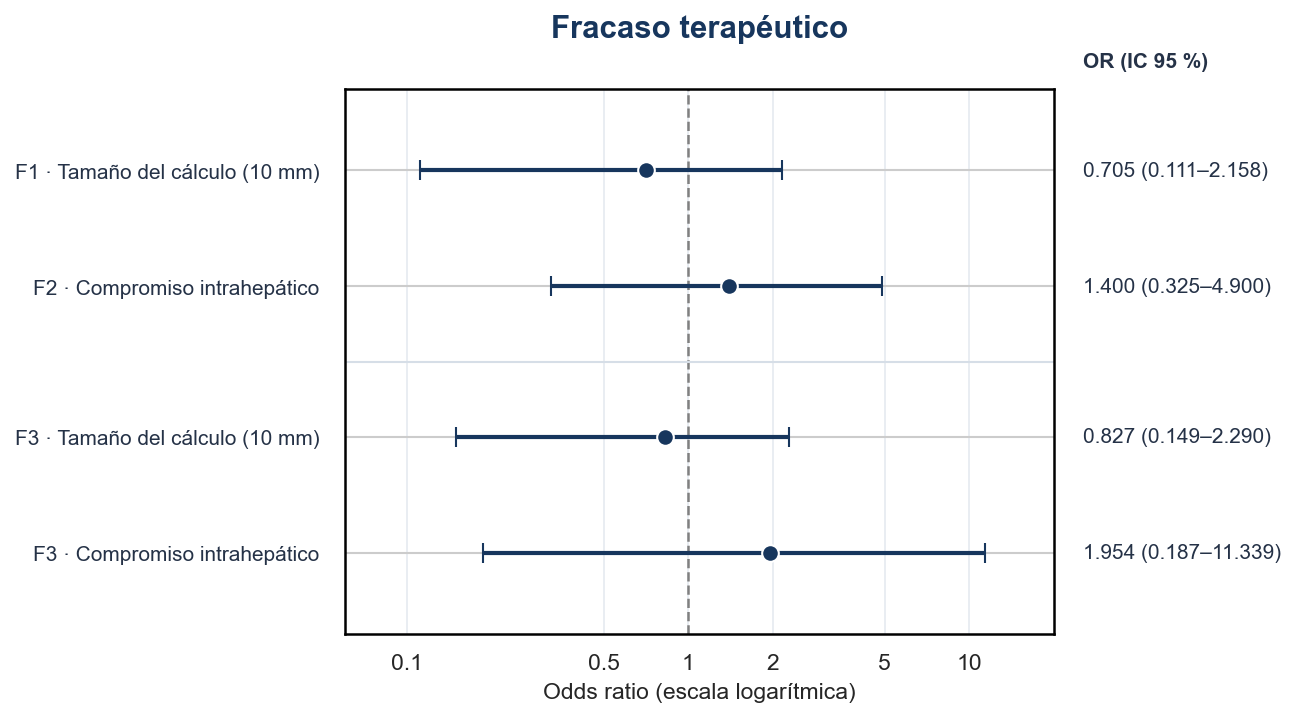

In [37]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator

datos = tabla_resultados_firth[
    tabla_resultados_firth["Modelo"].isin(["F1", "F2", "F3"])
].copy()

datos["Orden"] = datos["Modelo"].map({"F1": 0, "F2": 1, "F3": 2})
datos["Orden_predictor"] = datos["Predictor"].map({
    "Tamaño del cálculo (10 mm)": 0,
    "Compromiso intrahepático": 1
})

datos = datos.sort_values(["Orden", "Orden_predictor"]).reset_index(drop=True)

etiquetas = [
    f"{fila['Modelo']} · " + (
        "Tamaño del cálculo (10 mm)"
        if fila["Predictor"] == "Tamaño del cálculo (10 mm)"
        else "Compromiso intrahepático"
    )
    for _, fila in datos.iterrows()
]

y = np.array([3.5, 2.5, 1.2, 0.2])
azul = "#17365D"

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

for i, fila in datos.iterrows():
    estimacion = fila["OR"]
    inferior = fila["IC 95 % inferior"]
    superior = fila["IC 95 % superior"]

    ax.errorbar(
        estimacion, y[i],
        xerr=[[estimacion - inferior], [superior - estimacion]],
        fmt="o",
        color=azul,
        ecolor=azul,
        markersize=8,
        markeredgecolor="white",
        markeredgewidth=1,
        elinewidth=2,
        capsize=5,
        zorder=3
    )

    ax.text(
        1.04, y[i],
        f"{estimacion:.3f} ({inferior:.3f}–{superior:.3f})",
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=10,
        color="#253247",
        clip_on=False
    )

ax.axvline(1, color="#808080", linestyle="--", linewidth=1.2)
ax.axhline(1.85, color="#D6DEE7", linewidth=1)

ax.set_xscale("log")
ax.set_xlim(0.06, 20)
ax.set_ylim(-0.5, 4.2)
ax.set_xticks([0.1, 0.5, 1, 2, 5, 10])
ax.set_xticklabels(["0.1", "0.5", "1", "2", "5", "10"])
ax.xaxis.set_minor_locator(NullLocator())

ax.set_yticks(y)
ax.set_yticklabels(etiquetas, fontsize=10, color="#253247")
ax.tick_params(axis="y", length=0, pad=12)

ax.grid(axis="x", color="#E5EAF0", linewidth=0.8)
ax.set_axisbelow(True)

ax.set_title(
    "Fracaso terapéutico",
    fontsize=15,
    fontweight="bold",
    color=azul,
    pad=25
)

ax.set_xlabel("Odds ratio (escala logarítmica)", fontsize=11)

ax.text(
    1.04, 1.04, "OR (IC 95 %)",
    transform=ax.transAxes,
    ha="left",
    fontsize=10,
    fontweight="bold",
    color="#253247"
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

fig.subplots_adjust(left=0.29, right=0.72, top=0.83, bottom=0.17)

plt.show()




En los modelos de fracaso terapéutico, el tamaño del cálculo presentó una asociación negativa tanto en el análisis univariado (F1: OR = 0.705; IC 95 %: 0.111–2.158) como en el modelo conjunto (F3: OR = 0.827; IC 95 %: 0.149–2.290). Por su parte, el compromiso intrahepático mostró una asociación positiva en ambos ajustes, con OR de 1.400 en F2 y 1.954 en F3.

Sin embargo, todos los intervalos de confianza incluyen el valor 1, por lo que no se identificaron asociaciones estadísticamente significativas con el fracaso terapéutico. El modelo conjunto presentó una incertidumbre particularmente elevada para el compromiso intrahepático (IC 95 %: 0.187–11.339), lo que refleja la limitada precisión de esta estimación.


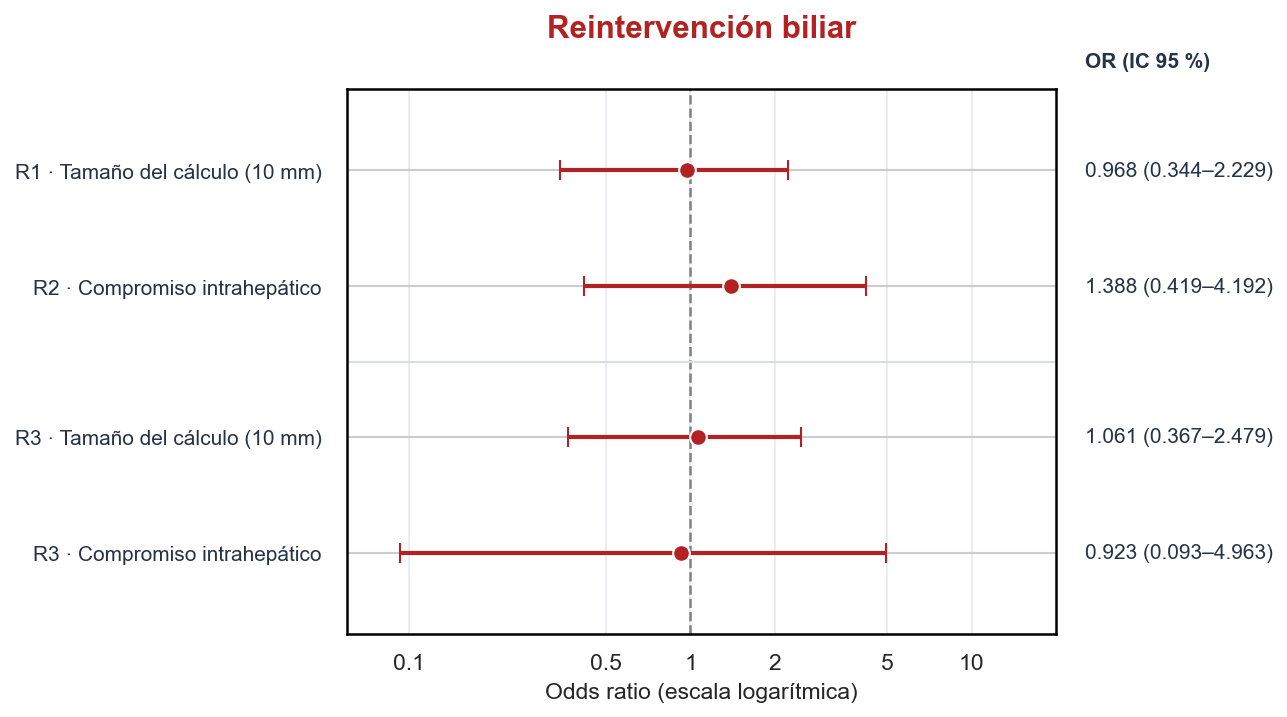

In [38]:

datos = tabla_resultados_firth[
    tabla_resultados_firth["Modelo"].isin(["R1", "R2", "R3"])
].copy()

datos["Orden"] = datos["Modelo"].map({"R1": 0, "R2": 1, "R3": 2})
datos["Orden_predictor"] = datos["Predictor"].map({
    "Tamaño del cálculo (10 mm)": 0,
    "Compromiso intrahepático": 1
})

datos = datos.sort_values(["Orden", "Orden_predictor"]).reset_index(drop=True)

etiquetas = [
    f"{fila['Modelo']} · " + (
        "Tamaño del cálculo (10 mm)"
        if fila["Predictor"] == "Tamaño del cálculo (10 mm)"
        else "Compromiso intrahepático"
    )
    for _, fila in datos.iterrows()
]

y = np.array([3.5, 2.5, 1.2, 0.2])
rojo = "#B22222"

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

for i, fila in datos.iterrows():
    estimacion = fila["OR"]
    inferior = fila["IC 95 % inferior"]
    superior = fila["IC 95 % superior"]

    ax.errorbar(
        estimacion, y[i],
        xerr=[[estimacion - inferior], [superior - estimacion]],
        fmt="o",
        color=rojo,
        ecolor=rojo,
        markersize=8,
        markeredgecolor="white",
        markeredgewidth=1,
        elinewidth=2,
        capsize=5,
        zorder=3
    )

    ax.text(
        1.04, y[i],
        f"{estimacion:.3f} ({inferior:.3f}–{superior:.3f})",
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=10,
        color="#253247",
        clip_on=False
    )

ax.axvline(1, color="#808080", linestyle="--", linewidth=1.2)
ax.axhline(1.85, color="#D6DEE7", linewidth=1)

ax.set_xscale("log")
ax.set_xlim(0.06, 20)
ax.set_ylim(-0.5, 4.2)
ax.set_xticks([0.1, 0.5, 1, 2, 5, 10])
ax.set_xticklabels(["0.1", "0.5", "1", "2", "5", "10"])
ax.xaxis.set_minor_locator(NullLocator())

ax.set_yticks(y)
ax.set_yticklabels(etiquetas, fontsize=10, color="#253247")
ax.tick_params(axis="y", length=0, pad=12)

ax.grid(axis="x", color="#E5EAF0", linewidth=0.8)
ax.set_axisbelow(True)

ax.set_title(
    "Reintervención biliar",
    fontsize=15,
    fontweight="bold",
    color=rojo,
    pad=25
)

ax.set_xlabel("Odds ratio (escala logarítmica)", fontsize=11)

ax.text(
    1.04, 1.04, "OR (IC 95 %)",
    transform=ax.transAxes,
    ha="left",
    fontsize=10,
    fontweight="bold",
    color="#253247"
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

fig.subplots_adjust(left=0.29, right=0.72, top=0.83, bottom=0.17)

plt.show()


En los modelos de reintervención biliar, el tamaño del cálculo presentó odds ratios cercanos a 1, tanto en el análisis univariado (R1: OR = 0.968; IC 95 %: 0.344–2.229) como en el modelo conjunto (R3: OR = 1.061; IC 95 %: 0.367–2.479), sin evidenciar una asociación clara con el desenlace.

El compromiso intrahepático mostró un OR de 1.388 en el modelo univariado (R2), mientras que en el modelo conjunto (R3) disminuyó a 0.923. No obstante, los intervalos de confianza de ambos ajustes incluyen el valor 1, por lo que estas asociaciones no fueron estadísticamente significativas. La amplitud del intervalo correspondiente a R3 (0.093–4.963) evidencia una considerable incertidumbre en la estimación.



### 4.2. Análisis de sensibilidad de los modelos

Se evalúa la estabilidad de las estimaciones mediante un análisis de sensibilidad por eliminación individual de observaciones (*leave-one-out*). Este procedimiento consiste en reajustar cada modelo excluyendo temporalmente un procedimiento y comparar los coeficientes obtenidos con los estimados utilizando la muestra completa.

El análisis permite identificar estimaciones especialmente sensibles a observaciones individuales, una consideración relevante debido al número limitado de eventos disponibles, particularmente en los modelos conjuntos F3 y R3.


In [39]:

resultados_sensibilidad = []

for nombre in ["F3", "R3"]:
    config = especificaciones[nombre]
    datos = datos_modelos[nombre]

    X, y = preparar_matriz_firth(
        datos,
        config["desenlace"],
        config["predictores"]
    )

    beta_original = ajustes_firth[nombre]["coeficientes"]

    for i in range(len(y)):
        X_reducida = np.delete(X, i, axis=0)
        y_reducida = np.delete(y, i)

        ajuste = ajustar_firth(X_reducida, y_reducida)

        for j, predictor in enumerate(config["predictores"], start=1):
            resultados_sensibilidad.append({
                "Modelo": nombre,
                "Predictor": predictor,
                "Observación excluida": i + 1,
                "OR original": np.exp(beta_original[j]),
                "OR recalculado": (
                    np.exp(ajuste["coeficientes"][j])
                    if ajuste["convergencia_numerica"]
                    else np.nan
                ),
                "Convergencia": ajuste["convergencia_numerica"]
            })

df_sensibilidad = pd.DataFrame(resultados_sensibilidad)

tabla_sensibilidad = (
    df_sensibilidad
    .groupby(["Modelo", "Predictor"])
    .agg(
        OR_original=("OR original", "first"),
        OR_minimo=("OR recalculado", "min"),
        OR_maximo=("OR recalculado", "max"),
        Ajustes_convergentes=("Convergencia", "sum"),
        Ajustes_totales=("Convergencia", "size")
    )
    .reset_index()
)

display(
    tabla_sensibilidad.style
    .hide(axis="index")
    .format({
        "OR_original": "{:.3f}",
        "OR_minimo": "{:.3f}",
        "OR_maximo": "{:.3f}"
    })
    .set_table_styles(estilo_revision)
    .set_caption("Tabla 16. Sensibilidad de los modelos conjuntos a la exclusión individual de observaciones")
)


Modelo,Predictor,OR_original,OR_minimo,OR_maximo,Ajustes_convergentes,Ajustes_totales
F3,COMPROMISO_INTRAHEPATICO,1.954,0.700,2.449,71,71
F3,TAMANO_10MM,0.827,0.558,1.006,71,71
R3,COMPROMISO_INTRAHEPATICO,0.923,0.309,1.154,71,71
R3,TAMANO_10MM,1.061,0.547,1.243,71,71



Los 142 reajustes realizados mediante el procedimiento *leave-one-out* alcanzaron convergencia numérica, lo que confirma la estabilidad computacional de ambos modelos conjuntos.

En el modelo de fracaso terapéutico (F3), el OR del tamaño del cálculo osciló entre 0.558 y 1.006, mientras que el correspondiente al compromiso intrahepático varió entre 0.700 y 2.449. Este último predictor mostró una sensibilidad considerable a la exclusión de observaciones individuales, con estimaciones que cambiaron de dirección respecto al valor nulo.

En el modelo de reintervención biliar (R3), el OR del tamaño del cálculo varió entre 0.547 y 1.243, y el del compromiso intrahepático entre 0.309 y 1.154. Ambos predictores presentaron estimaciones a ambos lados de OR = 1.

Los resultados muestran que, aunque los modelos convergen satisfactoriamente, las asociaciones estimadas pueden variar de forma importante al excluir un solo procedimiento, especialmente para el compromiso intrahepático en F3. Esto evidencia una estabilidad limitada de los efectos estimados en las muestras analizadas.




## 4. Conclusiones

Se implementaron seis modelos de regresión logística penalizada de Firth para evaluar la asociación entre el tamaño y la ubicación anatómica de los cálculos biliares y dos desenlaces clínicos: **fracaso terapéutico y reintervención biliar**.

Los modelos no identificaron asociaciones estadísticamente significativas entre los predictores evaluados y los desenlaces. Aunque se observaron diferencias en la dirección y magnitud de los odds ratios, todos los intervalos de confianza del 95 % incluyeron el valor 1, por lo que los resultados no permiten establecer asociaciones concluyentes.

Los procedimientos de optimización alcanzaron convergencia numérica satisfactoria. Sin embargo, el análisis de sensibilidad *leave-one-out* mostró variaciones importantes en algunas estimaciones, especialmente en los modelos conjuntos, lo que refleja su dependencia de observaciones individuales.

La principal limitación del análisis fue la disponibilidad de información clínica. El tamaño del cálculo y la ubicación anatómica presentaron registros incompletos, mientras que el número de cálculos no pudo incorporarse al modelado debido a su baja cobertura y al reducido número de eventos disponibles. Esto restringió el tamaño de las muestras analíticas y la precisión de las estimaciones.

En conclusión, **no se encontró evidencia estadística suficiente para establecer una asociación entre las características evaluadas de los cálculos biliares y el fracaso terapéutico o las reintervenciones biliares**.
